In [2]:
import numpy as np
from numpy.polynomial.legendre import leggauss as PLG
from scipy.integrate import quad
import math
import scipy.special as sp
import matplotlib.pyplot as plt
from scipy.sparse.linalg import gmres #pour résoudre le système linéaire 
import time


In [3]:
a = 5.0            # rayon du disque
#k = 3 # nombre d'onde
Nbre_elmt,Nbre_noeud = 100,100  # nombre de noeud,nombre element
N = 25             # nombre de mode 
m = 100 # nombre de point d'observation
nq = 4  # nombre de points pour la quadrature de Gauss Legendre 

vec_k = np.linspace(1, 100, 30)


def Geometrie_disque(R,N):

    angles = np.linspace(0,2*np.pi,N,endpoint = False)

    X = R*np.cos(angles) 
    Y = R*np.sin(angles) 
    Num_noeud = np.arange(N)
    
    # Noeuds = [ num_noeuds, xi,yi]
    Noeuds = np.transpose(np.vstack((Num_noeud,X,Y)))

    return Noeuds  




def Geometrie_ellipse(a, b, N):
    """
    Génère les nœuds pour la frontière d'une ellipse centrée en (0,0).
    
    Paramètres :
        a : Demi-grand axe selon X
        b : Demi-petit axe selon Y
        N : Nombre total de nœuds/éléments
    
    Retourne :
        Noeuds : Matrice (N, 3) où chaque ligne contient [num_noeud, X, Y]
    """
    # Échantillonnage de l'angle t dans [0, 2*pi[ (sens trigonométrique)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False)

    # Paramétrage standard de l'ellipse
    X = a * np.cos(angles) 
    Y = b * np.sin(angles) 

    Num_noeud = np.arange(N)
    
    # Structure uniforme avec tes autres fonctions : [num_noeud, xi, yi]
    Noeuds = np.transpose(np.vstack((Num_noeud, X, Y)))

    return Noeuds




def Maillage(Noeuds):

    N = len(Noeuds)

    #Elements =[ [ num_elem, noeud_debut, noeud_fin] ]

    Elements = np.array( [ [ i, i , (i+1)%N  ] for i in range(N)] )
    
    np.set_printoptions(suppress=True)
    
    
    
    Milieux = []
    Longueurs = []
    Normales = []

    for k in range(N):   # pour chaque élement 

        # On recupere les numeros des noeuds qui le constituent

        i_k = Elements[k,1]
        j_k = Elements[k,2] 

        # Noeuds de l'éléments 

        ni = Noeuds[i_k]
        
        nj = Noeuds[j_k]
 
        # coordonnées de chaque noeuds 
        
        xi = ni[1]
        yi = ni[2]

        xj = nj[1]
        yj = nj[2]

        # On calcule lepoint milieu  M_k

        x_M = (xi + xj)/2
        y_M = (yi + yj)/2

        M_k = [ float(x_M),float( y_M) ]
        Milieux.append(M_k)


        # Longueur de l'élément 

        dx = xj - xi
        dy = yj - yi

        lk = float(np.sqrt((dx)**2 + (dy)**2))
        Longueurs.append(lk)

        # Normale exterieure

        n_k = [float(dy/lk),
            float(-dx/lk)]

        Normales.append(n_k)

    Milieux = np.array(Milieux)
    Longueurs = np.array(Longueurs)
    Normales = np.array(Normales)

    return Noeuds,Elements,Milieux,Longueurs,Normales



def U_inc(r,theta):

    return np.exp(-1j*k*r*np.cos(theta))

def U_plus(r,theta,N,k,a):

    u_plus = 0 + 0j

    for n in range (-N,N+1):

        An = - (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a) 
        u_plus += An * sp.hankel1(n,k*r) * np.exp(1j*n*theta)
    return u_plus



# U_inc = lambda r,theta,k:np.exp(-1j*k*r*np.cos(theta))


## Fonction de Green de l'espace libre 2D 


def G(x,y):

    d = np.sqrt((x[0]-y[0])**2 + (x[1] - y[1])**2)
    return 1j/4 * sp.hankel1(0, k*d)

def G2(x,y):

    result = []
    for i in range (len(y)):
        yy = y[i]
        result.append(G(x,yy))
    return result


def dU_inc(r,theta,k):
    
    return -1j*k*np.cos(theta)*np.exp(-1j*k*r*np.cos(theta))

def q(r,theta,k,a,N):

    q = 0 + 0j

    for n in range(-N, N+1):

        q += (-k/2 * (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a)* (sp.hankel1(n-1,k*r)- sp.hankel1(n+1,k*r)) * np.exp(1j*n*theta))

    return q 

def P(r,theta,k,a,N):

    return -q(a,theta,k,a,N) - dU_inc(a,theta,k)


In [9]:
## Construction de la trace normale de P par approximation constante par élément

## On commence ici la construction de b 
t0 = time.perf_counter()
list_p = []

for k in vec_k:
    b = []

    b1 = a+5
    Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a, Nbre_noeud))

    zeta,W = PLG(nq) # noeuds et poids pour la quadrature de Gauss
    zeta = np.array(zeta)
    W = np.array(W)

    zetazeta = np.transpose(np.vstack((zeta,zeta))) 

    for e in range(Nbre_elmt):               # pour chaque élément 

        # On prend les numéros des noeuds qui le constituent
        num1 = Elements[e,1]
        num2 = Elements[e,2]
        
        n1 = Noeuds[num1]
        n2 = Noeuds[num2]
        # on récupère uniquement les coordonnés des noeuds sans les numéros
        n1 = n1[1:]
        n2 = n2[1:]

        # liste des points de Gauss sur l'élément 

        Nouv_zeta = (n2 + n1)/2 + zetazeta/2 *(n2 - n1) 

        # On calcule leurs coordonnées polaire 

        Nouv_zeta_polaire = []

        r = 0 
        theta = 0

        for x in Nouv_zeta : 

            r = np.sqrt(x[0]**2 + x[1]**2)

            theta = np.arctan2(x[1],x[0])
            
            Nouv_zeta_polaire.append([r,theta])

        Nouv_zeta_polaire = np.array(Nouv_zeta_polaire)

        # print(Nouv_zeta_polaire)

        
            

        #  liste des points de Gauss sur l'élément 

        WW = 0.5*Longueurs[e]*W

        ## On calcule donc bi 

        bi = - np.sum(WW*np.array([U_inc(zet[0],zet[1]) for zet in Nouv_zeta_polaire]))

        b.append(bi)

    b = np.array(b)



    ## On code la matrice A 

    gamma =  0.5772156649

    A = np.zeros((Nbre_elmt,Nbre_elmt), dtype = complex)

    zeta,W = PLG(nq)

    zeta = np.array(zeta)
    W = np.array(W) 
    zetazeta = np.transpose(np.vstack((zeta,zeta)))

    for e in range(Nbre_elmt):

        We = 0.5*Longueurs[e]*W

        # On prend les numéros des noeuds qui le constituent
        num1 = Elements[e,1]
        num2 = Elements[e,2]
        
        n1 = Noeuds[num1]
        n2 = Noeuds[num2]
        # on récupère uniquement les coordonnés des noeuds sans les numéros
        n1 = n1[1:]
        n2 = n2[1:]

        # liste des points de Gauss sur l'élément  e

        zeta_e = (n2 + n1)/2 + zetazeta/2 *(n2 - n1)
        
        for i in range(Nbre_noeud):

            Wi = We
                        
            num3 = Elements[i,1]
            num4 = Elements[i,2]

            n3 = Noeuds[num3]
            n4 = Noeuds[num4]

            n3 = n3[1:]
            n4 = n4[1:]

            zeta_i = (n4 + n3)/2 + zetazeta/2 *(n4 - n3)   # Points de Gauss sur l'élément i


            if( i != e):

                A[e,i] = np.sum(We*[np.sum(G2(zeta_e[l],zeta_i)*Wi) for l in range(nq)])

            if(i == e):

                # On fait des variables pour la lisibilité

                norm_ba = Longueurs[i]
                dbi = n4 - zeta_i 
                dai = n3 - zeta_i
                dbi_norm = np.sqrt(dbi[:, 0]**2 + dbi[:, 1]**2)
                dai_norm = np.sqrt(dai[:, 0]**2 + dai[:, 1]**2)
                tau_i = (1/norm_ba)*(n4 - n3)



                # On sépare en 2 termes
                terme1 = ((1j/4) - (1/(2*np.pi))*(np.log(k/2) + gamma) + (1/(2*np.pi))) * Longueurs[i]**2
                terme2 = 0

                #On fait la somme dans le deuxième terme 
                for l in range(nq):
                    terme2 += Wi[l]*(np.dot(dbi[l], tau_i*np.log(dbi_norm[l])) - np.dot(dai[l], tau_i*np.log(dai_norm[l])))

                #On les ajoute
                A[e, i] = terme1 - (1/(2*np.pi))*terme2


                

    # On résout le système linéaire

    p, info = gmres(A, b, tol=1e-10)
    list_p.append(p)



 k = 100.0
 Erreur_relative  = 0.9141940115102248:


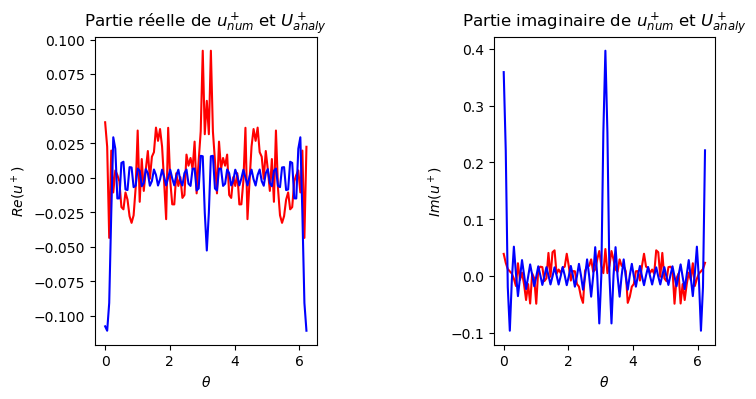

In [10]:
## On Couple les codes pour reconstruire le champs dans le domaine 

# Point d'observation 
angles = np.linspace(0,2*np.pi,m,endpoint = False)

Xobs = 5*a*np.cos(angles)
Yobs = 5*a*np.sin(angles)
Point_obs = np.transpose(np.vstack((Xobs,Yobs)))

list_uref = []
list_u = []



## On construit maintenant la matrice A 

for p in list_p:
    zeta,W = PLG(nq)       ## points et poinds de la quadrature de Gauss-Legendre sur [-1,1]

    zeta = np.array(zeta)
    W = np.array(W)
    zetazeta = np.zeros((len(zeta),2))
    zetazeta[:,0] = zeta
    zetazeta[:,1] = zeta

    AA = np.zeros((m,Nbre_elmt), dtype = complex)

    ## DOUBLE BOUCLE /!\
    for i in range(m):
        for e in range(Nbre_elmt):
            We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

            # On recupère les Noeuds qui constituent l'élément e
            
            # numéros des Noeuds qui le constituent

            ie = Elements[e,1]
            je = Elements[e,2]

            #noeud de l'élément 

            n1 = Noeuds[ie]
            n2 = Noeuds[je]
            #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
            n1 = n1[1:]
            n2 = n2[1:]

            ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
            #zetazeta = np.zeros((len(zeta),2))
            #zetazeta[:,0] = zeta
        # zetazeta[:,1] = zeta
        # print(zetazeta)

            nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
            

            AA[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))


    U = AA@p
    list_u.append(U)
    

print(f" k = {k}")



    # 4)  Validation : on compare les parties relle et parties immaginaire avec la solution analytique. 

for k in vec_k:
    Uref = U_plus(5*a,angles,N,k,a)   # Solution analytique sur le disque de rayon 5a
    list_uref.append(Uref)
    
# Erreur relative 

#Erreur = np.max(np.abs(U-Uref))/np.max(np.abs(Uref))
list_err = []

for i in range(len(list_u)):
    listdiff = np.abs(list_u[i] - list_uref[i])
    list_err.append(max(listdiff)/np.max(np.abs(list_uref[i])))


print(f" Erreur_relative  = {Erreur}:")

# On affiche les parties relles et partie imaginaires de la solution analytique et de la solution calculer

fig,ax = plt.subplots(1,2, figsize=(8, 4))
plt.subplots_adjust(hspace=0.4, wspace=0.8)

ax[0].plot(angles,U.real,'r',label = 'partie_relle Solution numerique')
ax[0].plot(angles,Uref.real,'b',label ='partie_relle Solution analytique')
ax[0].set_title(r"Partie réelle de $u^+_{num}$ et $U^+_{analy}$")
ax[0].set_xlabel(r"$\theta$")
ax[0].set_ylabel(r"$Re(u^+)$")


ax[1].plot(angles,U.imag,'r',label = 'partie_imag Solution numerique')
ax[1].plot(angles,Uref.imag,'b',label ='partie_imag Solution analytique')
ax[1].set_title(r"Partie imaginaire de $u^+_{num}$ et $U^+_{analy}$")
ax[1].set_xlabel(r"$\theta$")
ax[1].set_ylabel(r"$Im(u^+)$")

#plt.legend(loc="lower right")
plt.show()

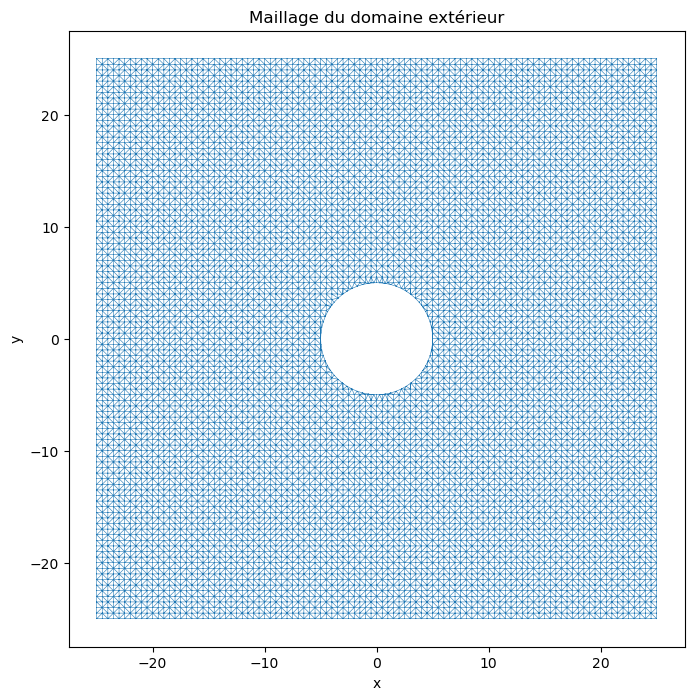

In [84]:

## Maillage du domaine exterieur de la fonctiere pour evaluer le champ diffracté avec VIZIR 4 qwsur un domaine 2D pas juste sur le disque de rayon 5a
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay


def Maillage_exterieur_disque(a, R_ext, h):

    # -------------------------------------------------------
    # 1. Grille de points dans le carré extérieur
    # -------------------------------------------------------

    x = np.arange(-R_ext, R_ext + h, h)
    y = np.arange(-R_ext, R_ext + h, h)

    X, Y = np.meshgrid(x, y)

    Points = np.column_stack((X.ravel(), Y.ravel()))


    # -------------------------------------------------------
    # 2. On supprime les points situés à l'intérieur
    #    de l'obstacle r < a
    # -------------------------------------------------------

    r = np.sqrt(Points[:, 0]**2 + Points[:, 1]**2)

    Points = Points[r >= a]


    # -------------------------------------------------------
    # 3. Ajout de points exactement sur Gamma
    # -------------------------------------------------------

    N_gamma = max(30, int(2*np.pi*a/h))

    theta = np.linspace(0, 2*np.pi, N_gamma, endpoint=False)

    Gamma = np.column_stack((
        a*np.cos(theta),
        a*np.sin(theta)
    ))

    Points = np.vstack((Points, Gamma))


    # -------------------------------------------------------
    # 4. Triangulation de Delaunay
    # -------------------------------------------------------

    triangulation = Delaunay(Points)

    Triangles = triangulation.simplices


    # -------------------------------------------------------
    # 5. Suppression des triangles qui tombent
    #    dans le disque
    # -------------------------------------------------------

    centres = Points[Triangles].mean(axis=1)

    r_centres = np.sqrt(
        centres[:, 0]**2 +
        centres[:, 1]**2
    )

    Triangles = Triangles[r_centres >= a]


    return Points, Triangles




def Maillage_exterieur_ellipse(a, b1, R_ext, h):
    # 1. Grille de points
    x = np.arange(-R_ext, R_ext + h, h)
    y = np.arange(-R_ext, R_ext + h, h)
    X, Y = np.meshgrid(x, y)
    Points = np.column_stack((X.ravel(), Y.ravel()))

    # 2. Suppression des points à l'intérieur de l'ellipse
    masque_ext = (Points[:, 0]**2 / a**2 + Points[:, 1]**2 / b1**2) >= 1.0
    Points = Points[masque_ext]

    # 3. Points exacts sur le contour de l'ellipse Gamma
    P_approx = np.pi * (3*(a + b1) - np.sqrt((3*a + b1)*(a + 3*b1))) # Périmètre approx.
    N_gamma = max(30, int(P_approx / h))
    theta = np.linspace(0, 2*np.pi, N_gamma, endpoint=False)
    
    Gamma = np.column_stack((
        a * np.cos(theta),
        b1 * np.sin(theta)
    ))
    Points = np.vstack((Points, Gamma))

    # 4. Triangulation de Delaunay
    triangulation = Delaunay(Points)
    Triangles = triangulation.simplices

    # 5. Suppression des triangles à l'intérieur de l'ellipse
    centres = Points[Triangles].mean(axis=1)
    masque_tri = (centres[:, 0]**2 / a**2 + centres[:, 1]**2 / b1**2) >= 1.0
    Triangles = Triangles[masque_tri]

    return Points, Triangles




a = 5.0
b1 = a+5 #grand axe

R_ext = 5*a

h = 0.5

Points_ext, Triangles_ext = Maillage_exterieur_disque(
    a,
    R_ext,
    h
)

plt.figure(figsize=(8, 8))

plt.triplot(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    linewidth=0.4
)

plt.gca().set_aspect("equal")

plt.xlabel("x")
plt.ylabel("y")

plt.title("Maillage du domaine extérieur")

plt.show()


Erreur relative = 0.9124587617142093


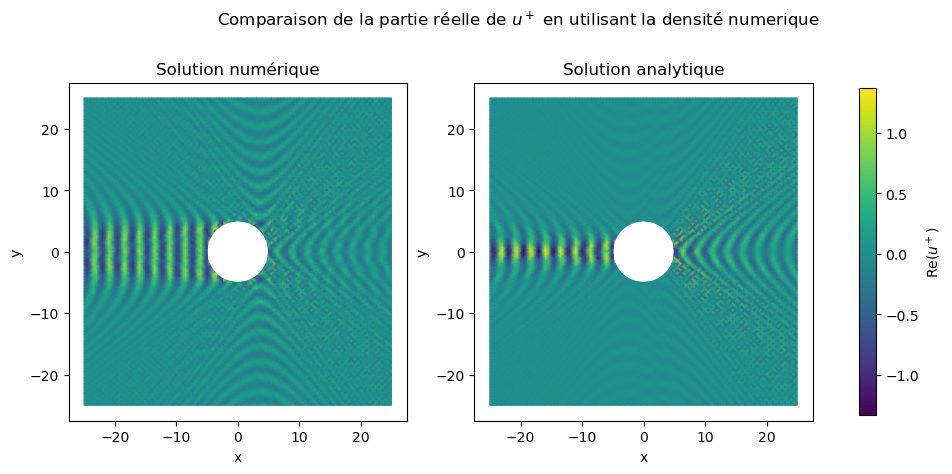

In [85]:
Point_obs = Points_ext

m = len(Point_obs)
A = np.zeros((m, Nbre_elmt), dtype=complex)
for i in range(m):
    for e in range(Nbre_elmt):
        We = Longueurs[e]/2*W  # We sont les poids sur l'élément e

        # On recupère les Noeuds qui constituent l'élément e
        
        # numéros des Noeuds qui le constituent

        ie = Elements[e,1]
        je = Elements[e,2]

        #noeud de l'élément 

        n1 = Noeuds[ie]
        n2 = Noeuds[je]
        #On prend les coordonnées sans les numéros pour facilement faire les calcules de (ae + be)/2 et (be - ae)/2
        n1 = n1[1:]
        n2 = n2[1:]

        ## On prend une matrice de taille (nq,2) dont toute le premiere et deuxieme colonne est zeta pour faciment faire le calcul avec numpy
        zetazeta = np.zeros((len(zeta),2))
        zetazeta[:,0] = zeta
        zetazeta[:,1] = zeta
       # print(zetazeta)

        nouv_zeta = (n2 - n1)/2 * zetazeta + (n2 + n1)/2   # points de quadrature sur l'éléments e 
        

        A[i,e] = np.sum(We*np.array([G(Point_obs[i],nouv_zeta[l]) for l in range(nq)]))




u_num = A @ p
u_re = np.real(u_num)
u_im = np.imag(u_num)

x = Point_obs[:, 0]
y = Point_obs[:, 1]

r = np.sqrt(x**2 + y**2)
theta = np.arctan2(y, x)

u_ref = U_plus(r, theta, N, k, a) 

Erreur_relative = (
    np.max(np.abs(u_num - u_ref))
    / np.max(np.abs(u_ref))
)

print("Erreur relative =", Erreur_relative)





import numpy as np
import matplotlib.pyplot as plt

# Parties réelle et imaginaire
u_num_re = np.real(u_num)
u_num_im = np.imag(u_num)

u_ref_re = np.real(u_ref)
u_ref_im = np.imag(u_ref)


# ============================================================
# 1. PARTIES REELLES
# ============================================================

# Même échelle de couleurs pour les deux figures
vmin_re = min(u_num_re.min(), u_ref_re.min())
vmax_re = max(u_num_re.max(), u_ref_re.max())

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

im1 = ax[0].tripcolor(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    u_num_re,
    shading="gouraud",
    vmin=vmin_re,
    vmax=vmax_re
)

ax[0].set_title("Solution numérique")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_aspect("equal")


im2 = ax[1].tripcolor(
    Points_ext[:, 0],
    Points_ext[:, 1],
    Triangles_ext,
    u_ref_re,
    shading="gouraud",
    vmin=vmin_re,
    vmax=vmax_re
)

ax[1].set_title("Solution analytique")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_aspect("equal")

# Une seule barre de couleur commune
fig.colorbar(
    im2,
    ax=ax,
    label=r"$\mathrm{Re}(u^+)$",
    shrink=0.85
)

fig.suptitle(r"Comparaison de la partie réelle de $u^+$ en utilisant la densité numerique")

plt.show()


Text(0, 0.5, 'erreur relative')

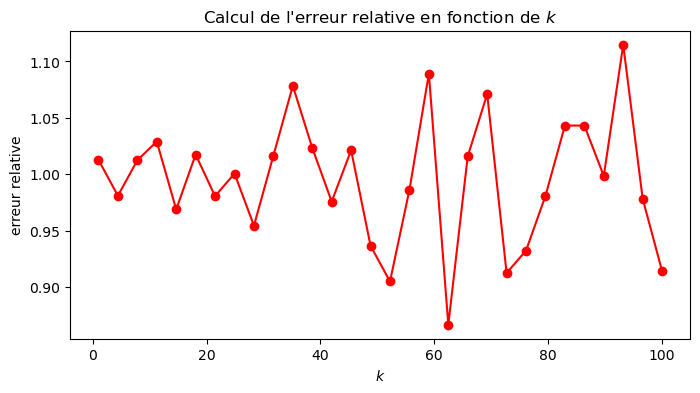

In [99]:
fig,ax = plt.subplots( figsize=(8, 4))
plt.subplots_adjust(hspace=0.4, wspace=0.8)


ax.plot(np.array(vec_k), np.array(list_err),'r-o',label = 'partie_relle Solution numerique')
ax.set_title(r"Calcul de l'erreur relative en fonction de $k$")
ax.set_xlabel(r"$k$")
ax.set_ylabel(r"erreur relative")
